# AED 2: Análisis bivariado · Campañas de depósitos bancarios (banco portugués)

## 1. Preparación de datos


### 1.1 Importación de librerias

In [32]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import seaborn as sns
from scipy.stats import mannwhitneyu, chi2_contingency

### 1.2 Estilo

In [33]:
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.figsize": (10, 6), "axes.titlesize": 14,
                     "axes.titleweight": "bold", "axes.labelsize": 12})
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

COLOR_PRINCIPAL = "#1f4e79"
COLOR_SECUNDARIO = "#c55a11"
COLORES_Y = {"no": "#9ecae1", "yes": COLOR_SECUNDARIO}

# Ubicación del archivo (misma lógica del AED 1)
CANDIDATOS = [
    Path(r"C:\Users\Roger\Videos\Modulo 3\trabajo final"),
    Path("/mnt/user-data/uploads"),
    Path("."),
    Path("data"),
]
DIRECTORIO = next((p for p in CANDIDATOS if (p / "bank-full.csv").exists()), None)
if DIRECTORIO is None:
    raise FileNotFoundError("No se encontró bank-full.csv")

### 1.3 Carga de datos desde archivos planos (CSV)

In [34]:
df = pd.read_csv(DIRECTORIO / "bank-full.csv", sep=";")
df["yb"] = (df["y"] == "yes").astype(int)  # 1 = contrató, 0 = no contrató

TASA_GLOBAL = df["yb"].mean() * 100
print(f"Clientes: {len(df):,} | Tasa de contratación global: {TASA_GLOBAL:.2f} %")

Clientes: 45,211 | Tasa de contratación global: 11.70 %


### 1.4 Funciones de apoyo
**Qué es:** Tres funciones reutilizables:
- `tasa_por_categoria`: calcula, para cada grupo, cuántos clientes hay y qué porcentaje contrató.
- `grafico_tasa`: dibuja esa tasa en barras, con la tasa global como línea de referencia.
- `boxplot_por_y`: compara la distribución de una variable numérica entre quienes contrataron y quienes no.

**Para qué sirve:** Evitar repetir código en cada celda y que todos los gráficos se vean igual.
**Cómo interpretarlo:** Las barras por encima de la línea discontinua contratan más que el promedio. Las que están por debajo, menos.

In [35]:
def tasa_por_categoria(data, columna, orden=None):
    # Tabla con clientes por grupo y su tasa de contratación en porcentaje
    tabla = data.groupby(columna).agg(
        clientes=("yb", "size"),
        contrataron=("yb", "sum"),
        tasa_pct=("yb", lambda s: s.mean() * 100),
    ).round(2)
    if orden is not None:
        return tabla.reindex(orden)
    return tabla.sort_values("tasa_pct", ascending=False)


def grafico_tasa(tabla, titulo, etiqueta_x, orden_etiquetas=None):
    # Barras con la tasa de contratación de cada grupo y línea del promedio global
    fig, ax = plt.subplots(figsize=(11, 6))
    sns.barplot(x=tabla.index.astype(str), y=tabla["tasa_pct"], color=COLOR_PRINCIPAL, ax=ax)
    for i, valor in enumerate(tabla["tasa_pct"]):
        ax.annotate(f"{valor:.1f}%", (i, valor), ha="center", va="bottom",
                    fontsize=9, xytext=(0, 3), textcoords="offset points")
    ax.axhline(TASA_GLOBAL, color=COLOR_SECUNDARIO, linestyle="--",
               label=f"Promedio global ({TASA_GLOBAL:.1f} %)")
    ax.set_title(titulo, pad=15)
    ax.set_xlabel(etiqueta_x)
    ax.set_ylabel("Clientes que contrataron (%)")
    ax.set_ylim(0, tabla["tasa_pct"].max() * 1.18)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    ax.legend(frameon=False)
    sns.despine()
    plt.tight_layout()
    plt.show()


def boxplot_por_y(columna, titulo, etiqueta_y, limite_percentil=None):
    # Diagrama de caja de una variable numérica separado por la variable objetivo
    datos = df.copy()
    if limite_percentil is not None:
        datos = datos[datos[columna] <= datos[columna].quantile(limite_percentil)]
    fig, ax = plt.subplots(figsize=(9, 6))
    sns.boxplot(data=datos, x="y", y=columna, hue="y", palette=COLORES_Y,
                showfliers=False, legend=False, width=0.5, ax=ax)
    ax.set_title(titulo, pad=15)
    ax.set_xlabel("¿Contrató el depósito?")
    ax.set_ylabel(etiqueta_y)
    sns.despine()
    plt.tight_layout()
    plt.show()

## 2. Variables numéricas frente a la contratación


En esta sección se compara el valor típico de cada variable numérica entre los que **sí** contrataron y los que **no**. Se usan dos medidas:
- **Media:** promedio. Sensible a valores extremos.
- **Mediana:** valor central. Más robusta cuando hay valores muy altos.

### 2.1 Media y mediana por grupo
**Qué es:** Una tabla con la media y la mediana de cada variable numérica, separadas por `y`.
**Para qué sirve:** Ver de un vistazo si los clientes que contratan tienen valores típicos distintos.

In [36]:
numericas = ["age", "balance", "day", "duration", "campaign", "pdays", "previous"]

tabla_medias = df.groupby("y")[numericas].mean().T.rename(columns={"no": "media_no", "yes": "media_si"})
tabla_medianas = df.groupby("y")[numericas].median().T.rename(columns={"no": "mediana_no", "yes": "mediana_si"})
display(pd.concat([tabla_medias, tabla_medianas], axis=1).round(2))

y,media_no,media_si,mediana_no,mediana_si
age,40.84,41.67,39.00,38.00
balance,"1,303.71","1,804.27",417.00,733.00
day,15.89,15.16,16.00,15.00
duration,221.18,537.29,164.00,426.00
campaign,2.85,2.14,2.00,2.00
pdays,36.42,68.70,-1.00,-1.00
previous,0.50,1.17,0.00,0.00


### 2.2 Edad según contratación

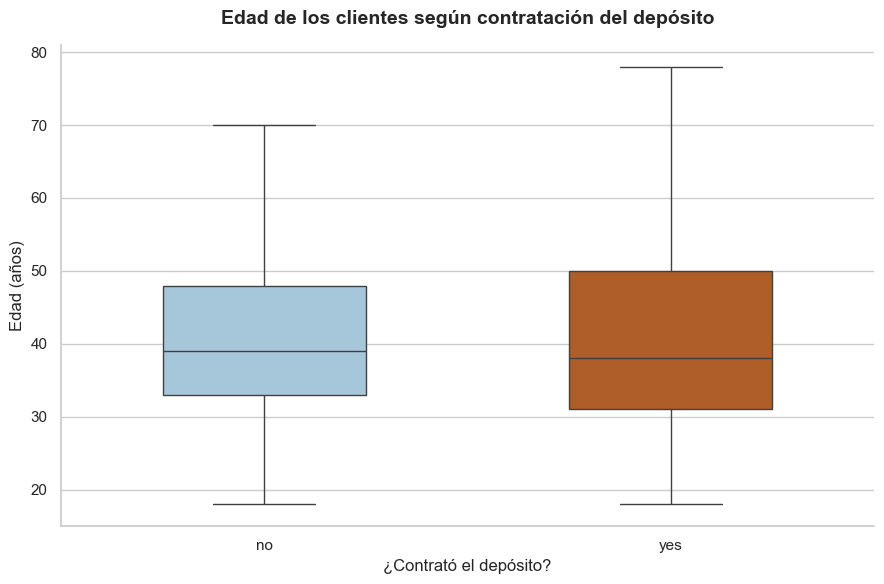

In [37]:
boxplot_por_y("age", "Edad de los clientes según contratación del depósito", "Edad (años)")

**Cómo interpretarlo:** Las dos cajas están casi en la misma posición. Las medianas son 39 y 38. Visualmente, la edad no distingue a quienes contratan. Esto coincide con la prueba de la celda anterior (p = 0,063). La relación con la edad no es lineal: aparece al analizar rangos de edad (sección 8).

### 2.3 Saldo según contratación

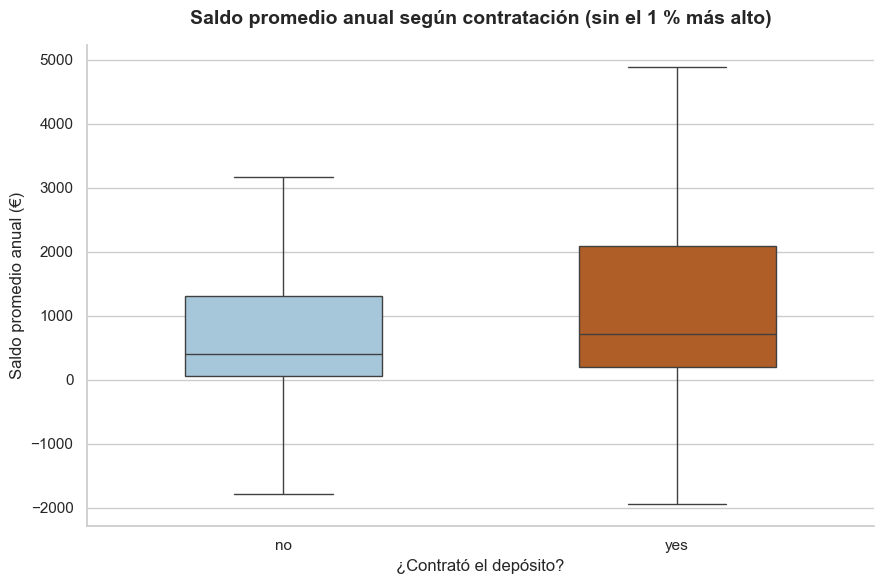

In [38]:
boxplot_por_y("balance", "Saldo promedio anual según contratación (sin el 1 % más alto)",
              "Saldo promedio anual (€)", limite_percentil=0.99)

**Cómo interpretarlo:** La caja de "sí" está desplazada hacia arriba. La mediana sube de **417 € a 733 €**, casi el doble. Además, la prueba es altamente significativa (p < 0,001). El saldo es una señal real: los clientes con más dinero disponible contratan más. Sin embargo, la dispersión es grande, por lo que el saldo por sí solo no separa a los clientes.

### 2.4 Duración de la llamada según contratación

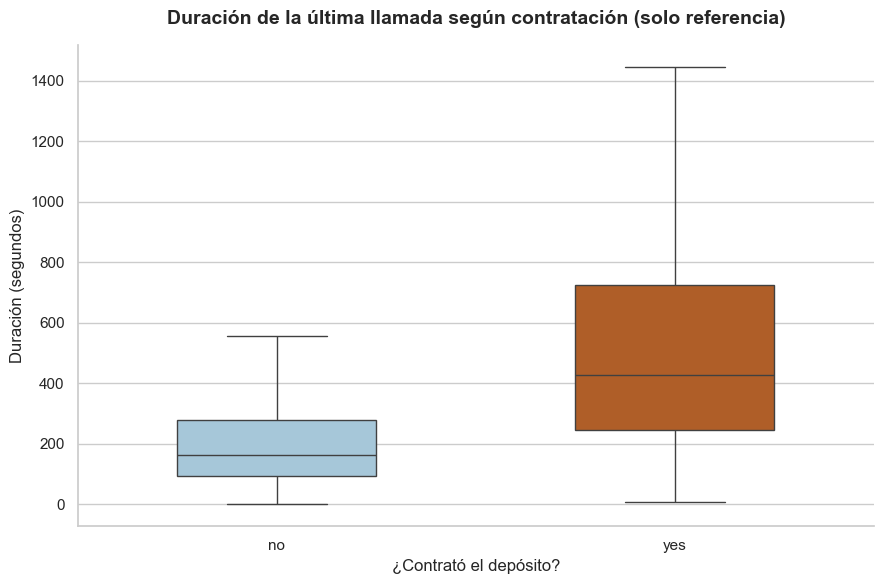

In [39]:
boxplot_por_y("duration", "Duración de la última llamada según contratación (solo referencia)",
              "Duración (segundos)")

**Cómo interpretarlo:** La mediana pasa de **164 s (2,7 min) a 426 s (7,1 min)**. Es la diferencia más grande del conjunto.

> **Advertencia importante:** esta relación **no sirve para predecir**. Las llamadas largas ocurren *porque* el cliente muestra interés, y la duración solo se conoce al terminar la llamada. Un modelo que la use parecerá muy bueno en las pruebas y fallará al decidir a quién llamar. Se incluye aquí solo para entender el fenómeno.

### 2.5 Número de contactos en la campaña según contratación

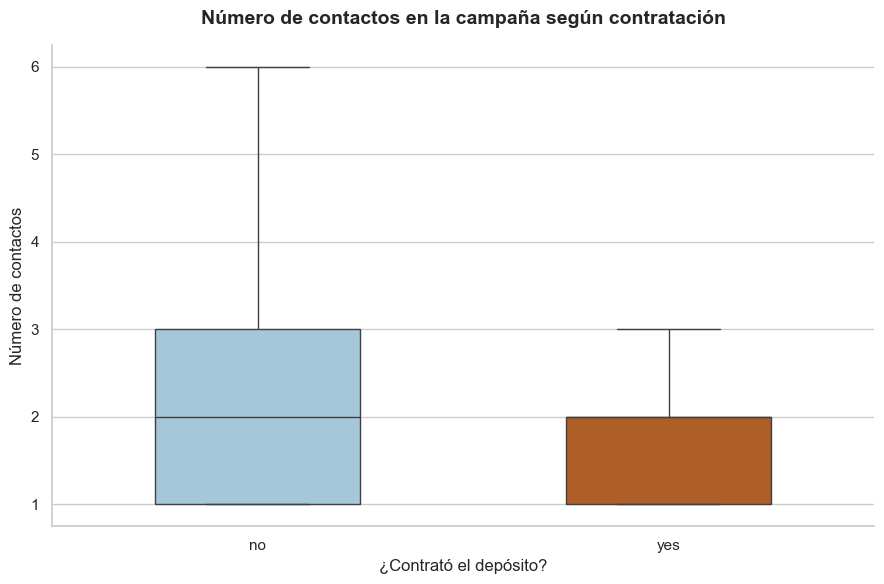

In [40]:
boxplot_por_y("campaign", "Número de contactos en la campaña según contratación",
              "Número de contactos", limite_percentil=0.99)

**Cómo interpretarlo:** La mediana es igual (2 contactos), pero la media baja de 2,8 a 2,1. Esto indica que los clientes que **no** contratan reciben más llamadas en promedio, y que hay casos con muchísimos contactos sin resultado. El análisis por rangos (sección 8) muestra el patrón con más claridad.

### 2.7 Historial previo: contactos anteriores y días desde el último contacto
**Qué es:** Tabla con la cantidad de contactos previos y los días desde el último contacto, separando a los clientes que tuvieron contacto previo (`pdays` distinto de -1).
**Para qué sirve:** Saber si tener historial con el banco se asocia con contratar.

In [41]:
con_contacto_previo = df[df["pdays"] != -1]
print(f"Clientes con contacto previo: {len(con_contacto_previo):,} ({len(con_contacto_previo)/len(df):.1%})")

display(con_contacto_previo.groupby("y")[["pdays", "previous"]].agg(["mean", "median", "count"]).round(1))

Clientes con contacto previo: 8,257 (18.3%)


pdays              previous             
      mean median count     mean median count
y                                            
no  234.20 232.00  6352     3.20   2.00  6352
yes 192.50 181.00  1905     3.20   2.00  1905

**Cómo interpretarlo:**
- Los clientes que contrataron y habían sido contactados antes tuvieron una mediana de **181 días** desde el último contacto. Los que no contrataron, **232 días**. Es decir, quienes contratan fueron contactados más recientemente.
- En la media de `previous`, los que contratan tienen **1,2** contactos previos frente a **0,5** de quienes no contratan. La mediana es 0 en ambos grupos: la mayoría no tuvo historial, y la diferencia viene de unos pocos clientes con muchos contactos previos

## 3. Variables categóricas frente a la contratación

Para cada variable categórica se calcula la **tasa de contratación** de cada grupo: qué porcentaje de sus clientes contrató. Esta es la forma más directa de ver si un grupo es más propenso que otro.

En cada celda se muestra la tabla y el gráfico. La línea discontinua marca el **promedio global de 11,7 %**.

### 3.1 Ocupación (`job`)
**Qué se mide:** La tasa de contratación para cada tipo de ocupación.
**Cómo interpretarlo:**
- **Estudiantes (28,7 %)** y **jubilados (22,8 %)** contratan casi el doble o más que el promedio.
- **Desempleados (15,5 %)** y **gerencia (13,8 %)** también están por encima.
- **Trabajadores manuales (7,3 %)**, **emprendedores (8,3 %)** y **servicios (8,9 %)** están claramente por debajo.
- La diferencia entre el grupo más alto y el más bajo es de más de 20 puntos porcentuales. Es una de las variables con mayor poder para distinguir clientes.

,clientes,contrataron,tasa_pct
job,,,
student,938,269,28.68
retired,2264,516,22.79
unemployed,1303,202,15.50
management,9458,1301,13.76
admin.,5171,631,12.20
self-employed,1579,187,11.84
unknown,288,34,11.81
technician,7597,840,11.06
services,4154,369,8.88


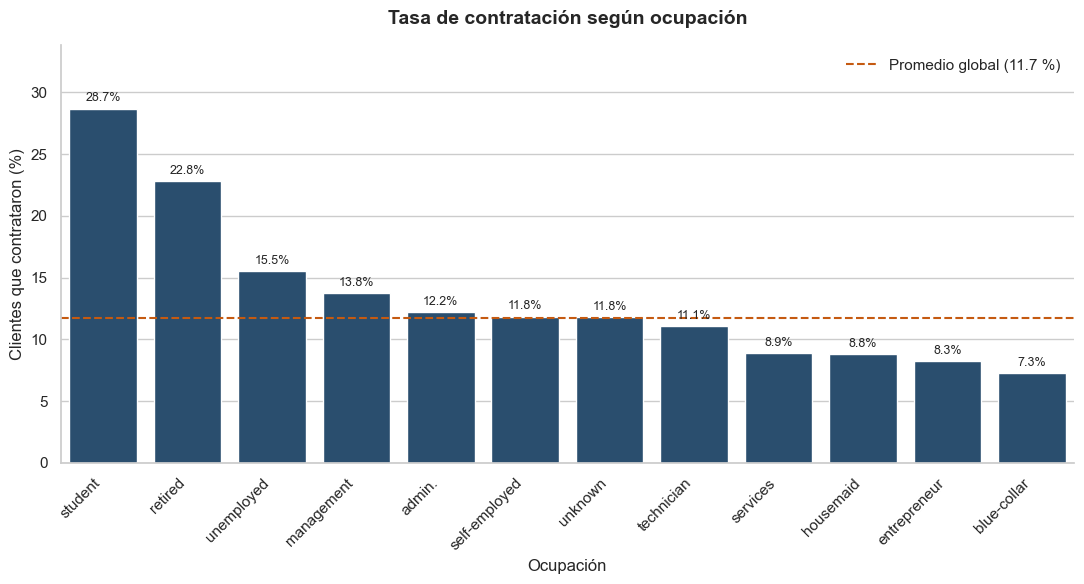

In [42]:
tabla_job = tasa_por_categoria(df, "job")
display(tabla_job)
grafico_tasa(tabla_job, "Tasa de contratación según ocupación", "Ocupación")

### 3.2 Estado civil (`marital`)
**Qué se mide:** La tasa de contratación según el estado civil.
**Cómo interpretarlo:**
- **Solteros (14,9 %)** contratan más que **casados (10,1 %)**.
- Los **divorciados (11,9 %)** están en un punto intermedio. En este conjunto, "divorciado" también incluye viudos.
- La diferencia es moderada: los solteros contratan casi un 50 % más que los casados.

,clientes,contrataron,tasa_pct
marital,,,
single,12790,1912,14.95
divorced,5207,622,11.95
married,27214,2755,10.12


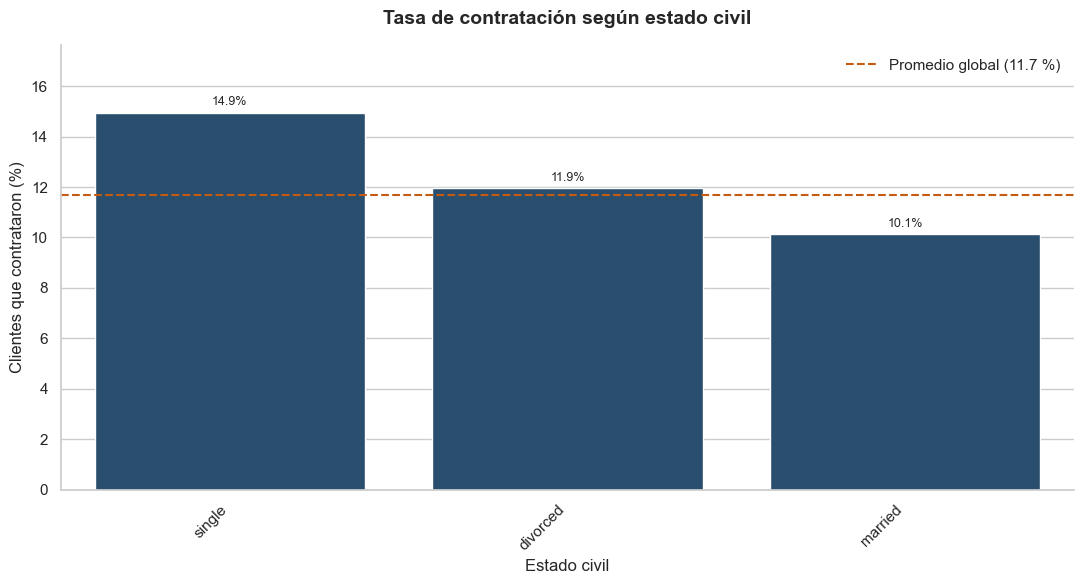

In [43]:
tabla_marital = tasa_por_categoria(df, "marital")
display(tabla_marital)
grafico_tasa(tabla_marital, "Tasa de contratación según estado civil", "Estado civil")

### 3.3 Nivel educativo (`education`)
**Qué se mide:** La tasa de contratación según el nivel de estudios.
**Cómo interpretarlo:**
- **Educación superior (15,0 %)** tiene la tasa más alta de las categorías conocidas.
- **Secundaria (10,6 %)** queda cerca del promedio.
- **Primaria (8,6 %)** es la más baja.
- Hay una tendencia clara: a más estudios, mayor tasa de contratación. La categoría `unknown` (13,6 %) no se debe interpretar como un grupo real.

,clientes,contrataron,tasa_pct
education,,,
tertiary,13301,1996,15.01
unknown,1857,252,13.57
secondary,23202,2450,10.56
primary,6851,591,8.63


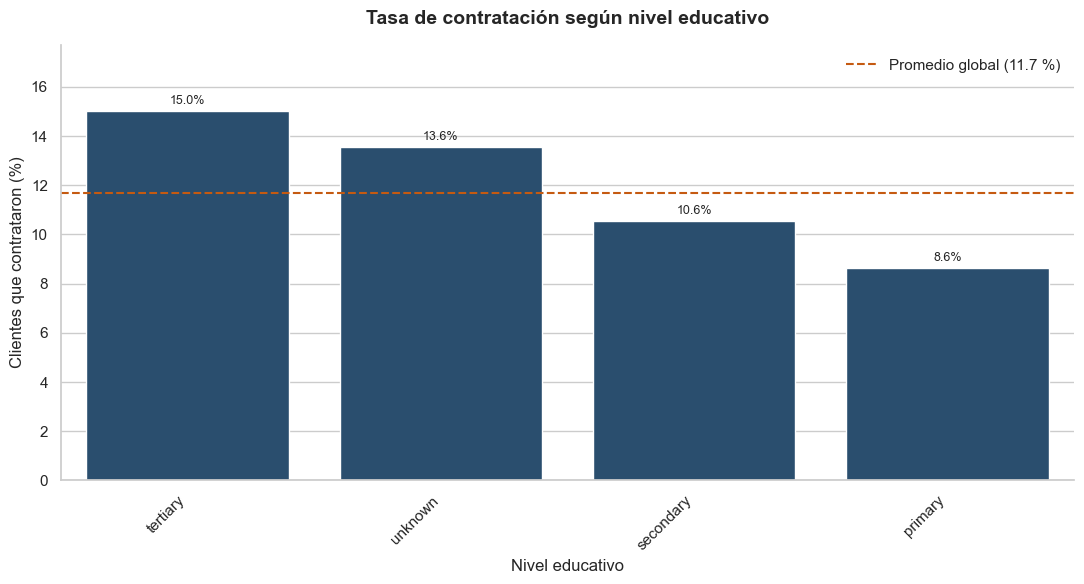

In [44]:
tabla_education = tasa_por_categoria(df, "education")
display(tabla_education)
grafico_tasa(tabla_education, "Tasa de contratación según nivel educativo", "Nivel educativo")

### 3.4 Crédito en incumplimiento (`default`)
**Qué se mide:** La tasa de contratación de quienes tienen un crédito en mora frente a quienes no.
**Cómo interpretarlo:**
- Quienes **no** tienen crédito en mora contratan al **11,8 %**.
- Quienes **sí** lo tienen contratan al **6,4 %**.
- La diferencia existe, pero el grupo con mora es muy pequeño (815 clientes, 1,8 %). Es una señal útil pero de alcance limitado.

,clientes,contrataron,tasa_pct
default,,,
no,44396,5237,11.80
yes,815,52,6.38


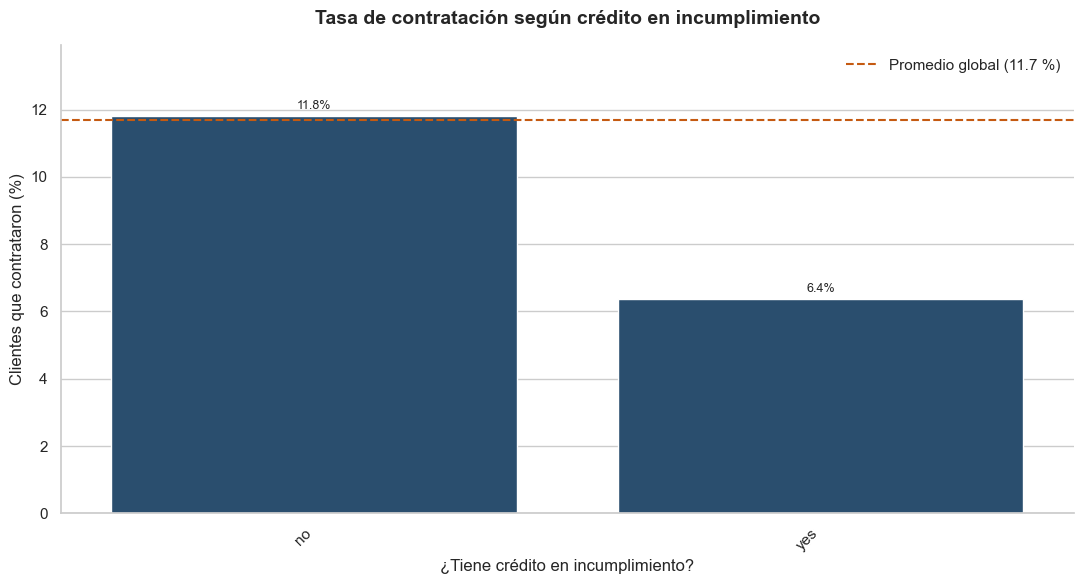

In [45]:
tabla_default = tasa_por_categoria(df, "default")
display(tabla_default)
grafico_tasa(tabla_default, "Tasa de contratación según crédito en incumplimiento",
             "¿Tiene crédito en incumplimiento?")

### 3.5 Préstamo de vivienda (`housing`)
**Qué se mide:** La tasa de contratación según tenga o no préstamo de vivienda.
**Cómo interpretarlo:**
- Sin préstamo de vivienda: **16,7 %** contrata.
- Con préstamo de vivienda: **7,7 %** contrata.
- Quien tiene hipoteca contrata a menos de la mitad de la tasa de quien no la tiene. Esta es una de las diferencias más marcadas de las variables binarias.

,clientes,contrataron,tasa_pct
housing,,,
no,20081,3354,16.70
yes,25130,1935,7.70


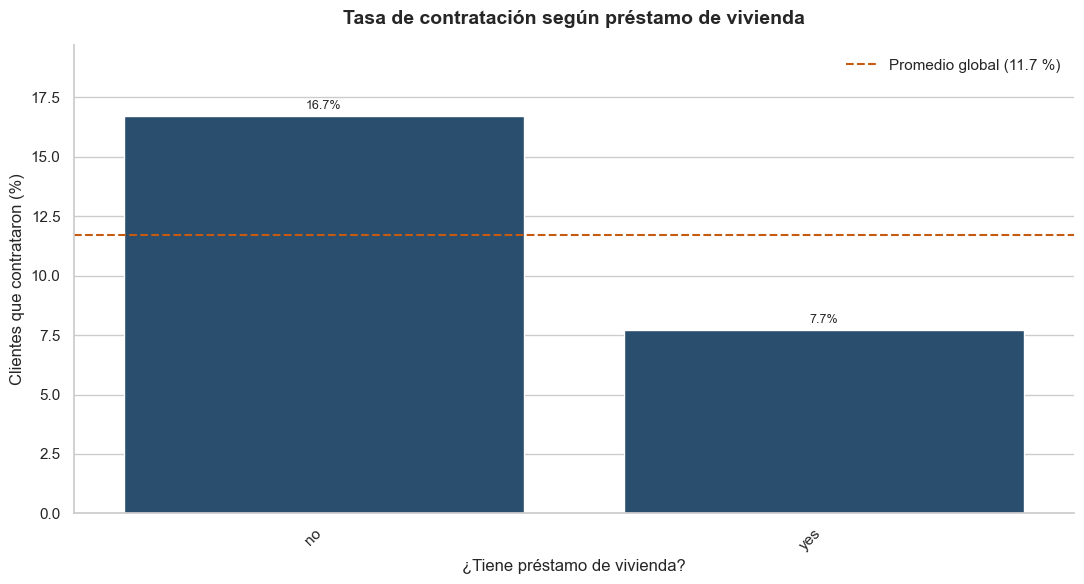

In [46]:
tabla_housing = tasa_por_categoria(df, "housing")
display(tabla_housing)
grafico_tasa(tabla_housing, "Tasa de contratación según préstamo de vivienda",
             "¿Tiene préstamo de vivienda?")

### 3.6 Préstamo personal (`loan`)
**Qué se mide:** La tasa de contratación según tenga o no préstamo personal.
**Cómo interpretarlo:**
- Sin préstamo personal: **12,7 %** contrata.
- Con préstamo personal: **6,7 %** contrata.
- Patrón parecido al del préstamo de vivienda, con una diferencia menor. Los clientes con deudas activas contratan menos.

,clientes,contrataron,tasa_pct
loan,,,
no,37967,4805,12.66
yes,7244,484,6.68


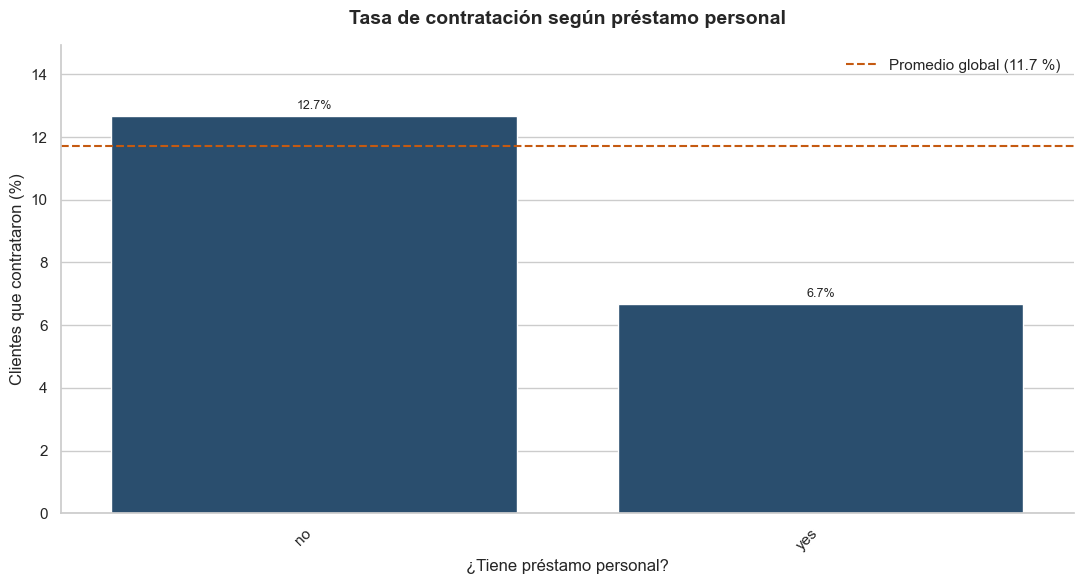

In [47]:
tabla_loan = tasa_por_categoria(df, "loan")
display(tabla_loan)
grafico_tasa(tabla_loan, "Tasa de contratación según préstamo personal",
             "¿Tiene préstamo personal?")

### 3.7 Canal de contacto (`contact`)
**Qué se mide:** La tasa de contratación según el medio por el que se contactó al cliente.
**Cómo interpretarlo:**
- **Celular (14,9 %)** y **teléfono fijo (13,4 %)** tienen tasas parecidas.
- **Desconocido (4,1 %)** tiene una tasa muy baja. Esto puede ser una señal importante: cuando no se registró el canal, probablemente fueron contactos de otro tipo o con registros incompletos. Conviene investigar por qué esos registros existen.
- Como la categoría `unknown` es el 29 % de los datos, esta diferencia tiene peso en el conjunto.

,clientes,contrataron,tasa_pct
contact,,,
cellular,29285,4369,14.92
telephone,2906,390,13.42
unknown,13020,530,4.07


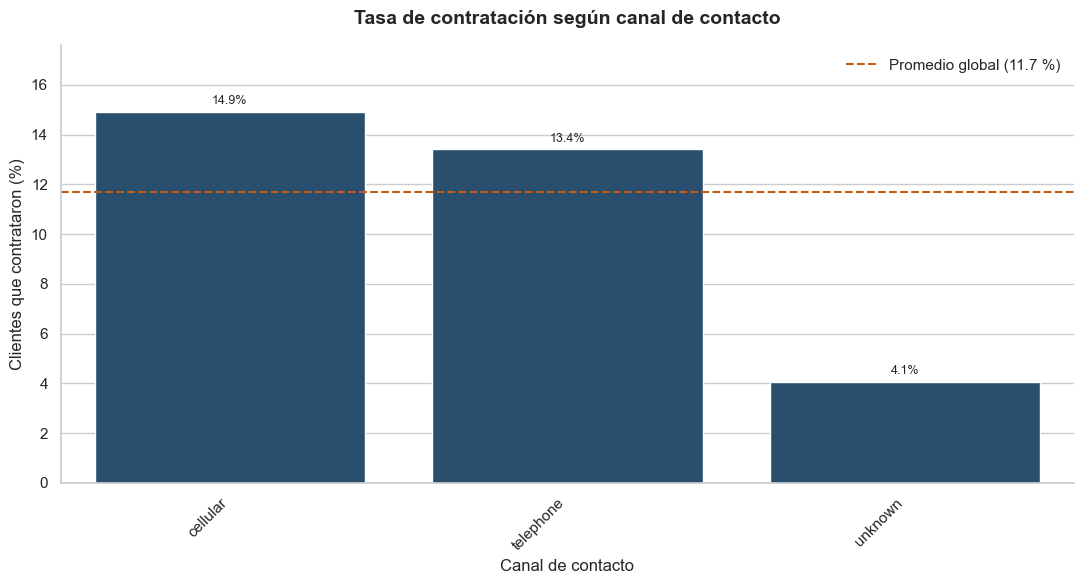

In [48]:
tabla_contact = tasa_por_categoria(df, "contact")
display(tabla_contact)
grafico_tasa(tabla_contact, "Tasa de contratación según canal de contacto", "Canal de contacto")

### 3.8 Mes del último contacto (`month`)
**Qué se mide:** La tasa de contratación según el mes en que se hizo el último contacto. Los meses se muestran en orden cronológico.
**Cómo interpretarlo:**
- **Marzo (52,0 %)**, **diciembre (46,7 %)**, **septiembre (46,5 %)** y **octubre (43,8 %)** tienen tasas muy altas.
- **Mayo (6,7 %)** tiene la tasa más baja, aunque es el mes con más llamadas (13.766).
- Los meses con tasas altas tienen pocos contactos (menos de 800 cada uno). Por eso sus porcentajes son menos estables.
- Conclusión práctica: la **efectividad de la campaña varía mucho según el mes**, y no solo según el esfuerzo de llamadas.

,clientes,contrataron,tasa_pct
month,,,
jan,1403,142,10.12
feb,2649,441,16.65
mar,477,248,51.99
apr,2932,577,19.68
may,13766,925,6.72
jun,5341,546,10.22
jul,6895,627,9.09
aug,6247,688,11.01
sep,579,269,46.46


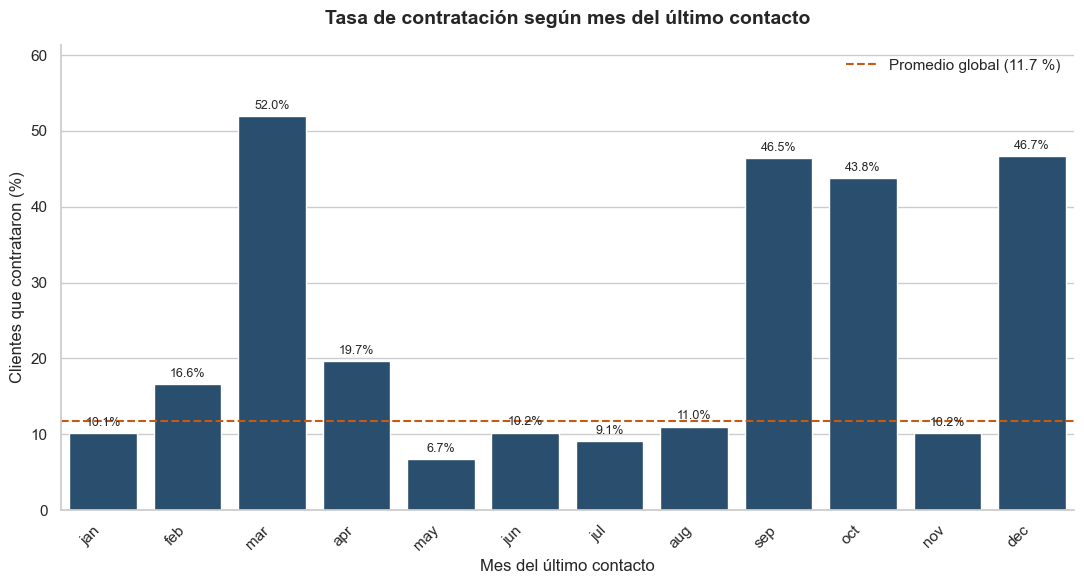

In [49]:
ORDEN_MESES = ["jan", "feb", "mar", "apr", "may", "jun",
               "jul", "aug", "sep", "oct", "nov", "dec"]

tabla_month = tasa_por_categoria(df, "month", orden=ORDEN_MESES)
display(tabla_month)
grafico_tasa(tabla_month, "Tasa de contratación según mes del último contacto", "Mes del último contacto")

### 3.9 Resultado de la campaña anterior (`poutcome`)
**Qué se mide:** La tasa de contratación según el resultado de la campaña anterior con ese mismo cliente.
**Cómo interpretarlo:**
- Si la campaña anterior **tuvo éxito**, el **64,7 %** vuelve a contratar. Es el grupo más receptivo de todo el conjunto.
- Si **falló**, contrata el 12,6 %. Si la categoría era **otra**, el 16,7 %.
- Cuando el resultado es **desconocido (9,2 %)**, está por debajo del promedio, pero casi todos los clientes están aquí (82 %). Esto significa que la gran mayoría no tiene historial de campaña.
- Un cliente que ya dijo "sí" antes es el mejor prospecto. Es la señal más fuerte para priorizar llamadas.

,clientes,contrataron,tasa_pct
poutcome,,,
success,1511,978,64.73
other,1840,307,16.68
failure,4901,618,12.61
unknown,36959,3386,9.16


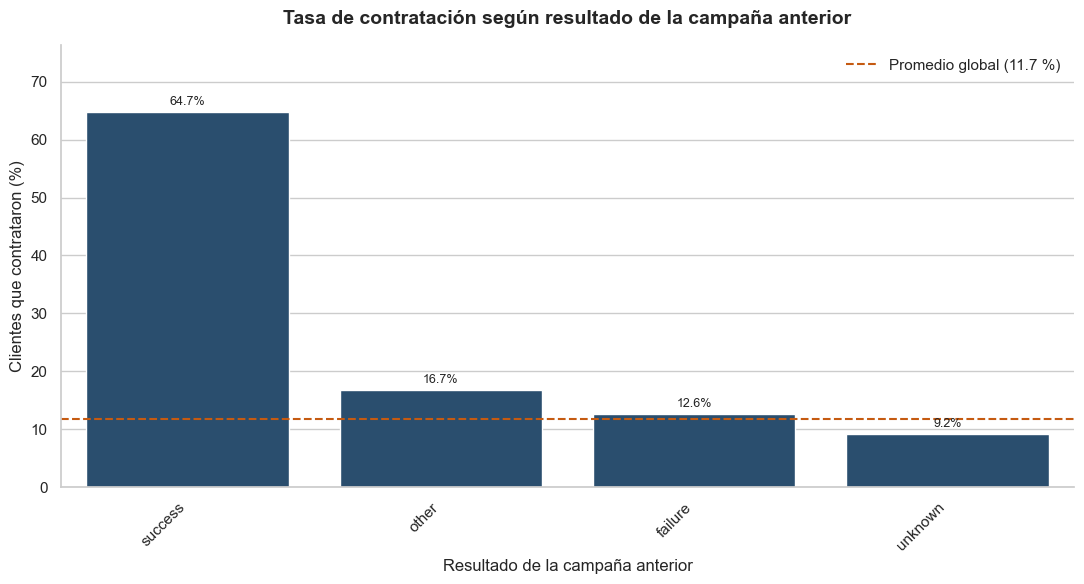

In [50]:
ORDEN_POUTCOME = ["success", "other", "failure", "unknown"]

tabla_poutcome = tasa_por_categoria(df, "poutcome", orden=ORDEN_POUTCOME)
display(tabla_poutcome)
grafico_tasa(tabla_poutcome, "Tasa de contratación según resultado de la campaña anterior",
             "Resultado de la campaña anterior")

## 5. Cruces entre dos variables categóricas

Hasta aquí cada variable se miró por separado. Un cruce muestra si el efecto de una variable **cambia** según el valor de otra. Por ejemplo, ¿el préstamo de vivienda pesa lo mismo en un cliente que tuvo éxito antes que en uno que no?

### 5.1 Resultado anterior × préstamo de vivienda
**Qué se mide:** La tasa de contratación para cada combinación de resultado anterior y préstamo de vivienda.
**Cómo interpretarlo:**
- Con **éxito previo**: sin hipoteca contrata el **70,1 %**; con hipoteca, el **52,9 %**.
- Con **fracaso previo**: sin hipoteca **23,1 %**; con hipoteca **8,3 %**.
- Con **desconocido**: sin hipoteca **12,4 %**; con hipoteca **6,4 %**.

En los tres casos, tener hipoteca **reduce** la tasa. La caída es de 17 puntos con éxito previo, de 15 puntos con fracaso previo (23,1 % a 8,3 %) y de 6 puntos con desconocido. Con éxito previo la caída es menor en términos relativos, pero el historial de éxito sigue siendo el factor más fuerte en cualquiera de los dos grupos.

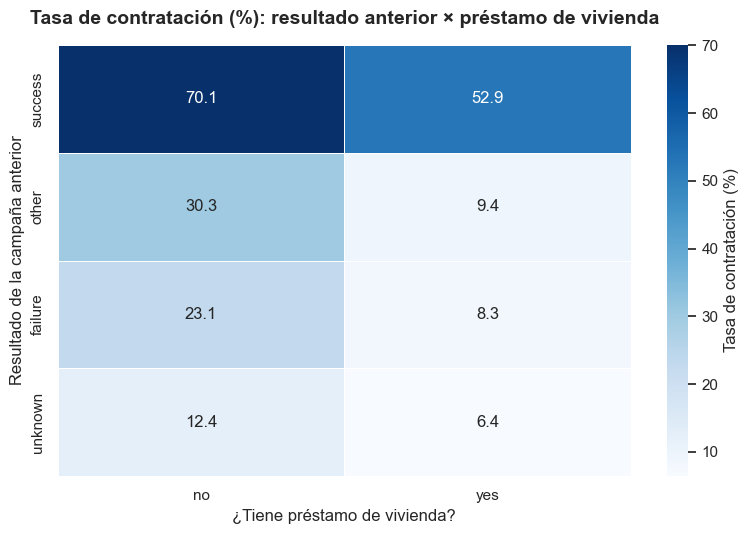

Clientes por combinación:


housing,no,yes
poutcome,,
success,1040,471
other,641,1199
failure,1431,3470
unknown,16969,19990


In [51]:
tasa_cruzada = df.pivot_table(index="poutcome", columns="housing", values="yb", aggfunc="mean") * 100
tamanos = df.pivot_table(index="poutcome", columns="housing", values="yb", aggfunc="size")

fig, ax = plt.subplots(figsize=(8, 5.5))
sns.heatmap(tasa_cruzada.loc[ORDEN_POUTCOME], annot=True, fmt=".1f", cmap="Blues",
            linewidths=0.5, cbar_kws={"label": "Tasa de contratación (%)"}, ax=ax)
ax.set_title("Tasa de contratación (%): resultado anterior × préstamo de vivienda", pad=15)
ax.set_xlabel("¿Tiene préstamo de vivienda?")
ax.set_ylabel("Resultado de la campaña anterior")
plt.tight_layout()
plt.show()

print("Clientes por combinación:")
display(tamanos.loc[ORDEN_POUTCOME])

### 5.2 Ocupación × nivel educativo
**Qué se mide:** La tasa de contratación para cada combinación de ocupación y educación. Solo se muestran combinaciones con al menos 200 clientes, para que los porcentajes sean estables.
**Cómo interpretarlo:**
- Los **estudiantes con educación secundaria (29,7 %)** y **jubilados con superior (27,6 %)** son los grupos más propensos.
- Dentro de los jubilados, la educación importa mucho: **superior 27,6 %**, **primaria 22,4 %**, **secundaria 21,0 %**.
- Dentro de los estudiantes, la educación importa menos: 29,7 % con secundaria y 26,5 % con superior.
- Conclusión: **la ocupación y la educación actúan juntas**. Un jubilado con estudios superiores se parece más a un estudiante que a otro jubilado con menos estudios.

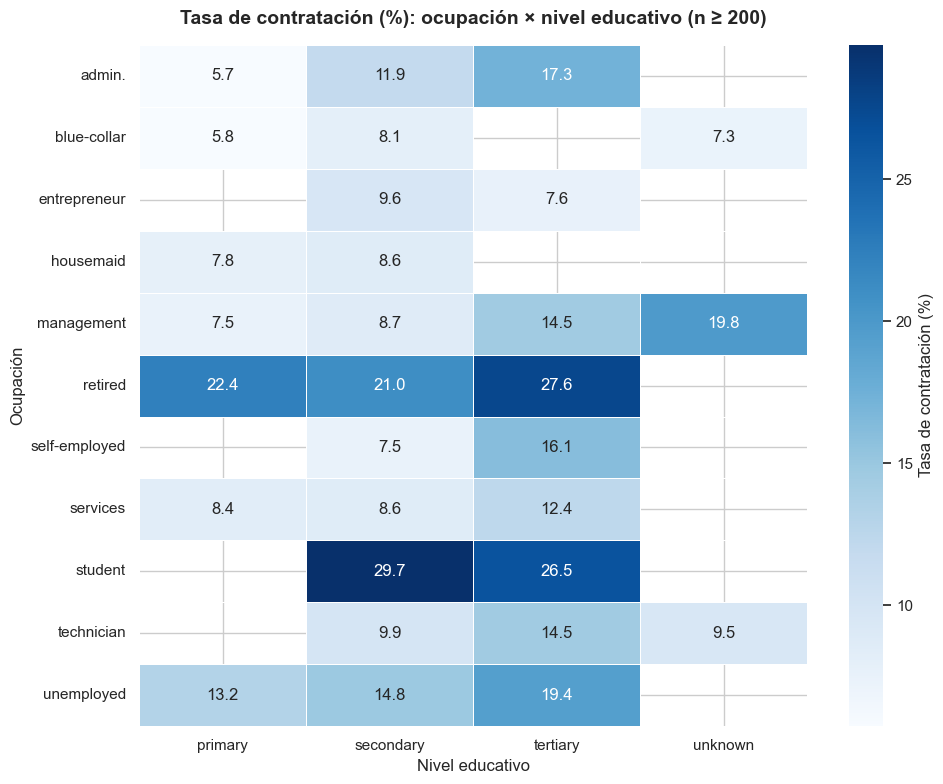

In [52]:
tasa_ocup_educ = df.groupby(["job", "education"]).agg(clientes=("yb", "size"), tasa=("yb", "mean"))
tasa_ocup_educ = tasa_ocup_educ[tasa_ocup_educ["clientes"] >= 200].copy()
tasa_ocup_educ["tasa"] *= 100

matriz = tasa_ocup_educ["tasa"].unstack("education")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(matriz, annot=True, fmt=".1f", cmap="Blues", linewidths=0.5,
            cbar_kws={"label": "Tasa de contratación (%)"}, ax=ax)
ax.set_title("Tasa de contratación (%): ocupación × nivel educativo (n ≥ 200)", pad=15)
ax.set_xlabel("Nivel educativo")
ax.set_ylabel("Ocupación")
plt.tight_layout()
plt.show()

## 6. Relación entre variables numéricas

Ahora se miran pares de variables numéricas. Se usa la correlación de **Spearman** en lugar de Pearson, porque mide relaciones **monótonas** (que suben o bajan juntas) sin depender de que la relación sea una recta. Además, es más robusta con valores extremos, como los saldos.

La escala va de −1 a +1:
- Menos de 0,1 en valor absoluto: prácticamente nula.
- Entre 0,1 y 0,3: débil.
- Entre 0,3 y 0,5: moderada.
- Más de 0,5: fuerte.

### 6.1 Matriz de correlaciones de Spearman
**Qué es:** Un mapa de calor con la correlación entre cada par de variables numéricas.
**Para qué sirve:** Ver si hay variables que se mueven juntas (redundantes) o que son independientes entre sí.
**Cómo interpretarlo:**
- **`pdays` y `previous` (0,99):** correlación casi perfecta. Ambas miden lo mismo (historial de contacto). Usar las dos en un modelo duplica la misma información.
- **`day` y `campaign` (0,14):** débil. En los días con más llamadas hay un poco más de contactos.
- **`campaign` y `duration` (−0,11):** débil y negativa. Cuando hay muchos contactos, las llamadas tienden a ser algo más cortas.
- **`age` y `balance` (0,10):** débil. Los clientes mayores tienen saldos algo más altos.
- **Casi todos los demás pares:** cercanos a cero. Las variables numéricas son en gran medida independientes entre sí.

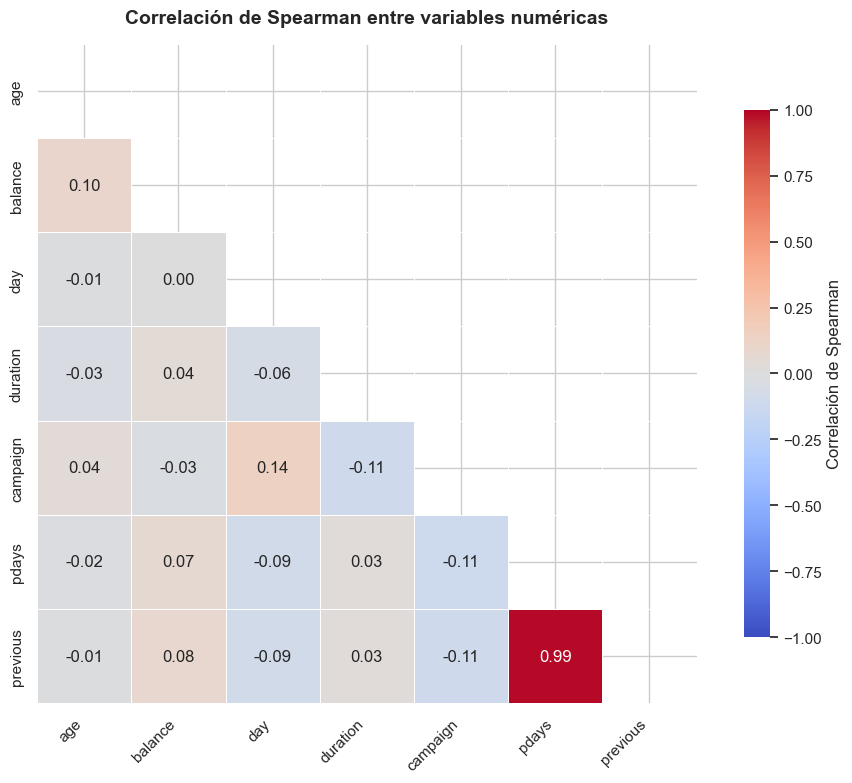

In [53]:
variables_numericas = ["age", "balance", "day", "duration", "campaign", "pdays", "previous"]
corr_spearman = df[variables_numericas].corr(method="spearman")

mascara = np.triu(np.ones_like(corr_spearman, dtype=bool))
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_spearman, mask=mascara, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, center=0, square=True, linewidths=0.5,
            cbar_kws={"shrink": 0.8, "label": "Correlación de Spearman"}, ax=ax)
ax.set_title("Correlación de Spearman entre variables numéricas", pad=15)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 7. Variables numéricas según categorías

Aquí se cruza una variable categórica con una numérica para ver cómo cambia el valor típico de la segunda según la primera. Se usa la **mediana** porque es robusta a valores extremos.

### 7.1 Saldo mediano según nivel educativo
**Qué se mide:** La mediana del saldo anual para cada nivel educativo.
**Cómo interpretarlo:**
- **Superior (577 €)** y **desconocido (568 €)** tienen los saldos más altos.
- **Primaria (403 €)** y **secundaria (392 €)** están más abajo.
- Los clientes con más estudios tienen, en general, más saldo. Esto ayuda a explicar por qué la educación se asocia con la contratación: los clientes con más recursos son más propensos a invertir en un depósito.

,mediana_saldo_€
education,
tertiary,577.00
unknown,568.00
primary,403.00
secondary,392.00


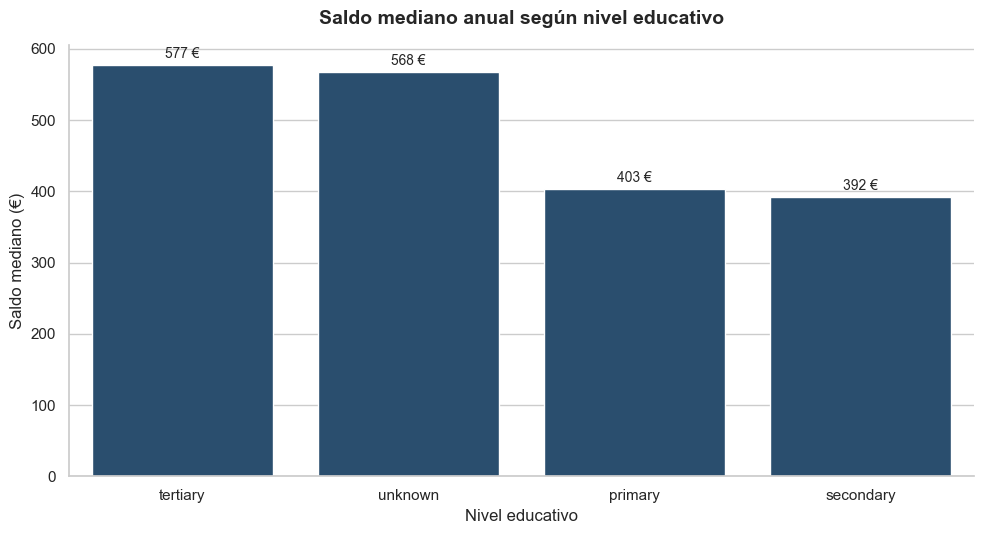

In [54]:
mediana_balance_educ = df.groupby("education")["balance"].median().sort_values(ascending=False)
display(mediana_balance_educ.to_frame("mediana_saldo_€"))

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(x=mediana_balance_educ.index, y=mediana_balance_educ.values, color=COLOR_PRINCIPAL, ax=ax)
for i, valor in enumerate(mediana_balance_educ.values):
    ax.annotate(f"{valor:,.0f} €", (i, valor), ha="center", va="bottom",
                fontsize=10, xytext=(0, 3), textcoords="offset points")
ax.set_title("Saldo mediano anual según nivel educativo", pad=15)
ax.set_xlabel("Nivel educativo")
ax.set_ylabel("Saldo mediano (€)")
sns.despine()
plt.tight_layout()
plt.show()

### 7.2 Edad mediana según ocupación
**Qué se mide:** La mediana de la edad para cada ocupación.
**Cómo interpretarlo:**
- **Estudiantes (26 años)** son los más jóvenes.
- **Jubilados (59 años)** son los más mayores.
- El resto se agrupa entre 37 y 47 años.
- Esto explica el patrón por edad de la sección 8: los extremos de edad son grupos muy distintos, no solo "más jóvenes" o "más mayores".

,mediana_edad
job,
student,26.00
services,37.00
technician,37.00
admin.,38.00
management,38.00
blue-collar,39.00
self-employed,39.00
unemployed,40.00
entrepreneur,41.00


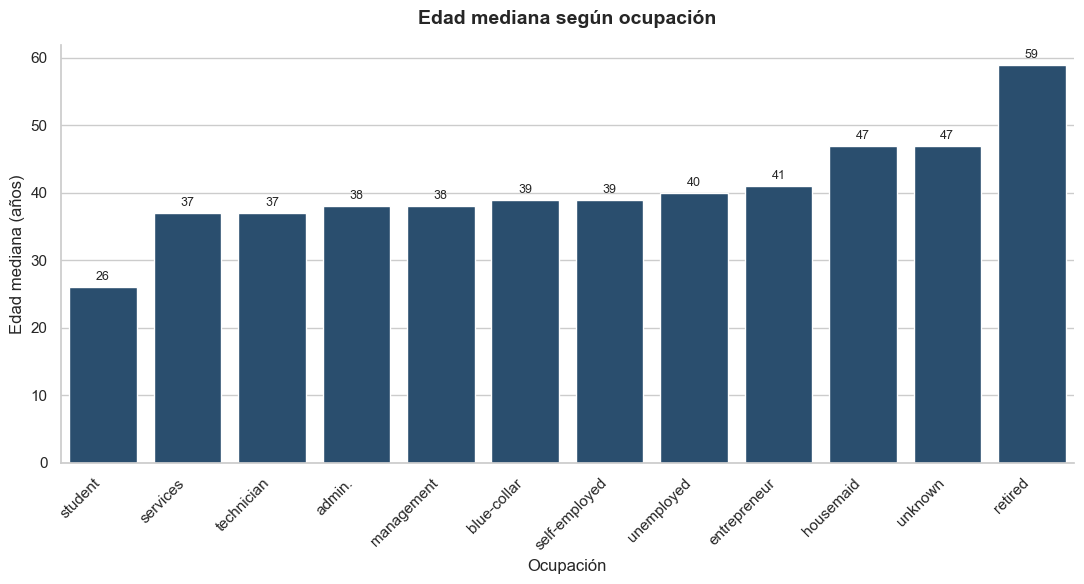

In [55]:
mediana_edad_ocup = df.groupby("job")["age"].median().sort_values()
display(mediana_edad_ocup.to_frame("mediana_edad"))

fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(x=mediana_edad_ocup.index, y=mediana_edad_ocup.values, color=COLOR_PRINCIPAL, ax=ax)
for i, valor in enumerate(mediana_edad_ocup.values):
    ax.annotate(f"{valor:.0f}", (i, valor), ha="center", va="bottom",
                fontsize=9, xytext=(0, 3), textcoords="offset points")
ax.set_title("Edad mediana según ocupación", pad=15)
ax.set_xlabel("Ocupación")
ax.set_ylabel("Edad mediana (años)")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
sns.despine()
plt.tight_layout()
plt.show()

## 8. Tasa de contratación por rangos

Algunas variables numéricas no tienen una relación lineal con `y`. Agruparlas en rangos permite ver el patrón con claridad.

### 8.1 Tasa de contratación por rangos de edad
**Qué se mide:** La tasa de contratación en intervalos de edad.
**Cómo interpretarlo:**
- **Hasta 25 años: 24,0 %**. Muy alta.
- **26 a 35 años: 12,0 %** y **36 a 55 años: 9,4 %**. Son las tasas más bajas.
- **56 a 65 años: 14,1 %**.
- **Más de 65 años: 42,6 %**. La tasa más alta, aunque el grupo es pequeño (751 clientes).

**Lectura sencilla:** la relación con la edad tiene forma de **U**. Los jóvenes y, sobre todo, los mayores de 65 contratan mucho más que el grupo de mediana edad. Por eso la comparación de medianas (sección 2.3) no detectó diferencia: los dos extremos se compensan.

C:\Users\Roger\AppData\Local\Temp\ipykernel_21116\3411691533.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tabla = data.groupby(columna).agg(


,clientes,contrataron,tasa_pct
rango_edad,,,
18-25,1336,320,23.95
26-35,15571,1869,12.00
36-45,13856,1301,9.39
46-55,9548,893,9.35
56-65,4149,586,14.12
66 o más,751,320,42.61


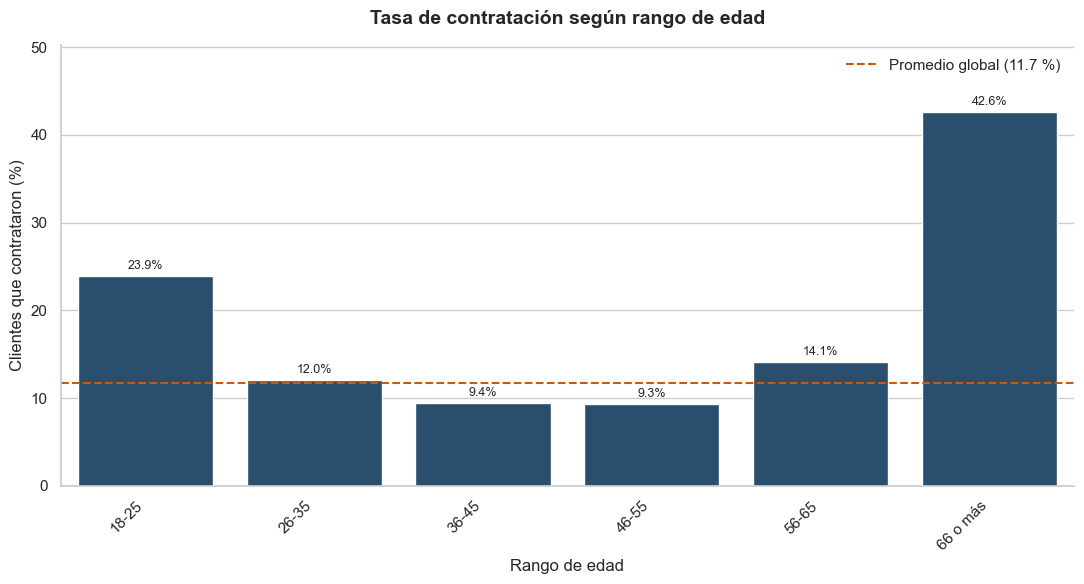

In [57]:
bins_edad = [17, 25, 35, 45, 55, 65, 100]
etiquetas_edad = ["18-25", "26-35", "36-45", "46-55", "56-65", "66 o más"]
df["rango_edad"] = pd.cut(df["age"], bins=bins_edad, labels=etiquetas_edad)

tabla_edad = tasa_por_categoria(df, "rango_edad", orden=etiquetas_edad)
display(tabla_edad)
grafico_tasa(tabla_edad, "Tasa de contratación según rango de edad", "Rango de edad")

### 8.2 Tasa de contratación por cuartiles de saldo
**Qué se mide:** La tasa de contratación en cuatro grupos de igual tamaño, ordenados por saldo.
**Cómo interpretarlo:**
- **Primer cuarto (hasta 72 €): 7,2 %.**
- **Segundo (72 a 448 €): 10,9 %.**
- **Tercero (448 a 1.428 €): 12,5 %.**
- **Cuarto (más de 1.428 €): 16,2 %.**

**Lectura sencilla:** la tasa sube de forma **constante** con el saldo. Quien tiene más de 1.428 € contrata más del doble que quien tiene menos de 72 €. Es una señal consistente, aunque la dispersión dentro de cada grupo sigue siendo grande.

C:\Users\Roger\AppData\Local\Temp\ipykernel_21116\3411691533.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tabla = data.groupby(columna).agg(


,clientes,contrataron,tasa_pct
cuartil_saldo,,,
Q1 (bajo),11317,819,7.24
Q2,11291,1230,10.89
Q3,11306,1415,12.52
Q4 (alto),11297,1825,16.15


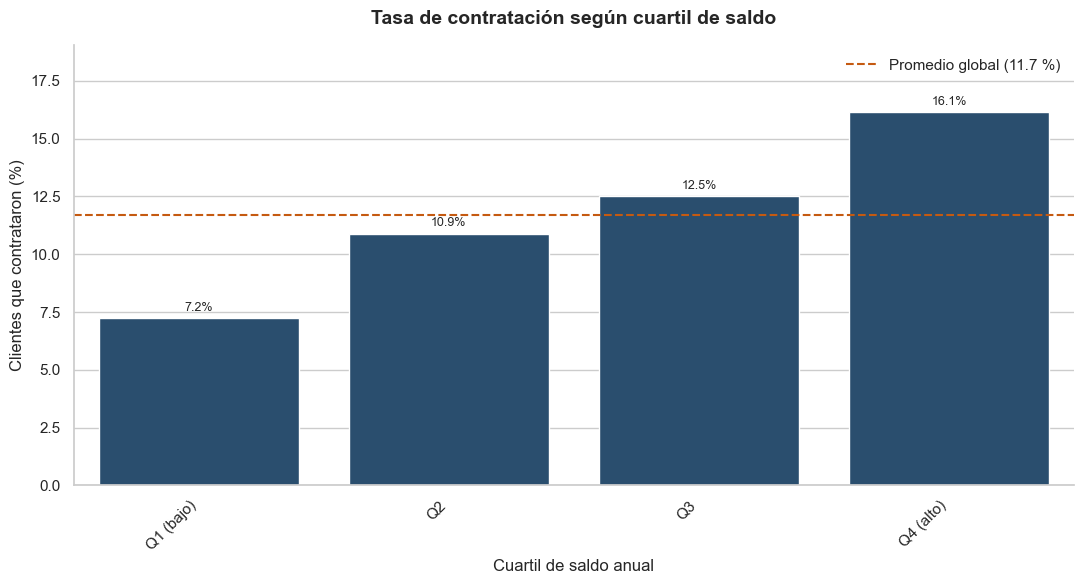

In [59]:
df["cuartil_saldo"] = pd.qcut(df["balance"], 4, labels=["Q1 (bajo)", "Q2", "Q3", "Q4 (alto)"])

tabla_saldo = tasa_por_categoria(df, "cuartil_saldo", orden=["Q1 (bajo)", "Q2", "Q3", "Q4 (alto)"])
display(tabla_saldo)
grafico_tasa(tabla_saldo, "Tasa de contratación según cuartil de saldo", "Cuartil de saldo anual")

### 8.3 Tasa de contratación según número de contactos en la campaña
**Qué se mide:** La tasa de contratación según cuántas veces se contactó al cliente en esta campaña.
**Cómo interpretarlo:**
- **1 contacto: 14,6 %**.
- **2 o 3 contactos: alrededor de 11 %.**
- **4 o 5 contactos: 8,6 %.**
- **6 a 10 contactos: 6,5 %.**
- **Más de 10 contactos: 3,9 %.**

**Lectura sencilla:** cuantas más llamadas se hacen al mismo cliente en la campaña, **menor** es la probabilidad de que contrate. Llamar por encima de unas pocas veces tiene rendimientos decrecientes. Esta es una de las conclusiones más útiles para la gestión de la campaña.

C:\Users\Roger\AppData\Local\Temp\ipykernel_21116\3411691533.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tabla = data.groupby(columna).agg(


,clientes,contrataron,tasa_pct
rango_contactos,,,
1,17544,2561,14.60
2,12505,1401,11.20
3,5521,618,11.19
4-5,5286,456,8.63
6-10,3159,206,6.52
Más de 10,1196,47,3.93


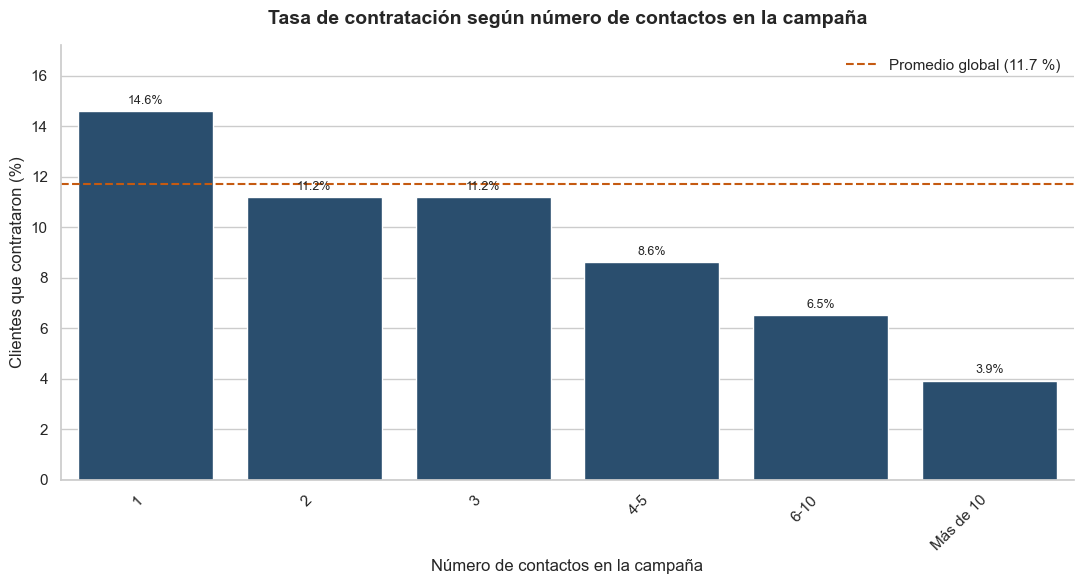

In [60]:
bins_campana = [0, 1, 2, 3, 5, 10, 100]
etiquetas_campana = ["1", "2", "3", "4-5", "6-10", "Más de 10"]
df["rango_contactos"] = pd.cut(df["campaign"], bins=bins_campana, labels=etiquetas_campana)

tabla_campana = tasa_por_categoria(df, "rango_contactos", orden=etiquetas_campana)
display(tabla_campana)
grafico_tasa(tabla_campana, "Tasa de contratación según número de contactos en la campaña",
             "Número de contactos en la campaña")

### 8.4 Tasa de contratación según contactos previos
**Qué se mide:** La tasa de contratación según cuántas veces se había contactado al cliente antes de esta campaña.
**Cómo interpretarlo:**
- **Ninguno: 9,2 %.**
- **Uno: 21,0 %.**
- **2 o 3: 23,1 %.**
- **4 a 10: 26,7 %** (el máximo).
- **Más de 10: 18,4 %**, aunque es un grupo pequeño (294 clientes).

**Lectura sencilla:** tener un historial de contactos previos **duplica** la tasa de contratación frente a no tenerlo. Pero la relación no es siempre creciente: con demasiados contactos previos la tasa vuelve a bajar. Este patrón sugiere que la relación es real pero no lineal.

C:\Users\Roger\AppData\Local\Temp\ipykernel_21116\3411691533.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tabla = data.groupby(columna).agg(


,clientes,contrataron,tasa_pct
rango_previos,,,
0,36954,3384,9.16
1,2772,583,21.03
2-3,3248,750,23.09
4-10,1943,518,26.66
Más de 10,294,54,18.37


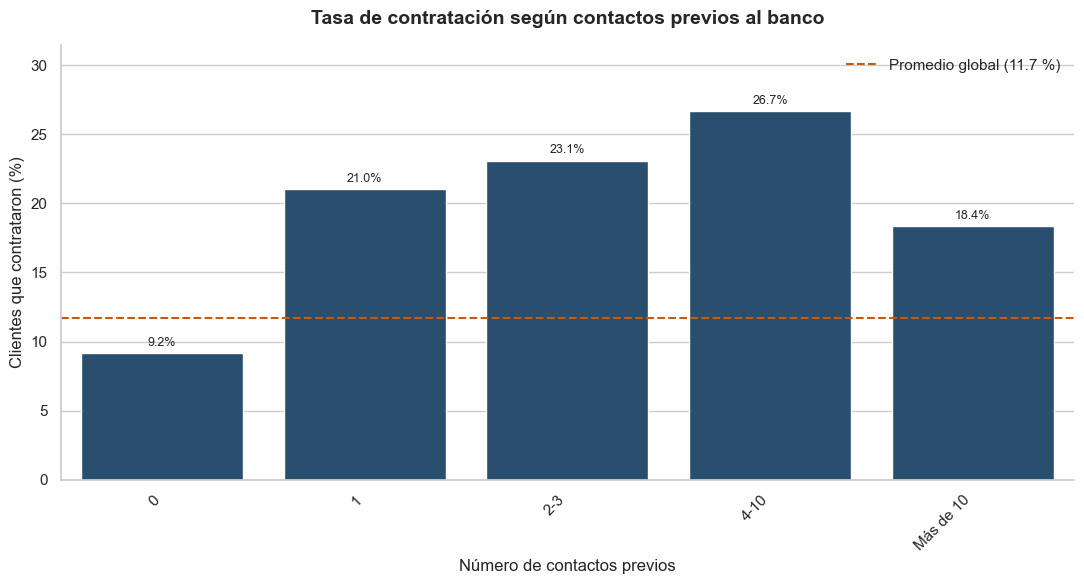

In [61]:
bins_previos = [-1, 0, 1, 3, 10, 300]
etiquetas_previos = ["0", "1", "2-3", "4-10", "Más de 10"]
df["rango_previos"] = pd.cut(df["previous"], bins=bins_previos, labels=etiquetas_previos)

tabla_previos = tasa_por_categoria(df, "rango_previos", orden=etiquetas_previos)
display(tabla_previos)
grafico_tasa(tabla_previos, "Tasa de contratación según contactos previos al banco",
             "Número de contactos previos")

### 8.5 Tasa de contratación según duración de la llamada (solo referencia)
**Qué se mide:** La tasa de contratación según cuánto duró la llamada.
**Cómo interpretarlo:**
- Llamadas de hasta 100 s: **1,1 %**.
- De 100 a 200 s: **5,5 %**.
- De 200 a 300 s: **11,7 %**.
- De 300 a 500 s: **17,1 %**.
- De 500 a 1.000 s: **38,1 %**.
- Más de 1.000 s: **59,7 %**.

**Lectura sencilla:** la relación es muy fuerte: las llamadas largas son mucho más propensas a terminar en contratación. **Pero esto no es utilizable para decidir a quién llamar**, porque la duración se conoce al final. Sirve para entender el proceso de venta: una conversación larga indica interés.

C:\Users\Roger\AppData\Local\Temp\ipykernel_21116\3411691533.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tabla = data.groupby(columna).agg(


,clientes,contrataron,tasa_pct
rango_duracion,,,
Hasta 100 s,10880,117,1.08
100-200 s,13989,770,5.50
200-300 s,8065,944,11.70
300-500 s,6903,1181,17.11
500-1000 s,4313,1645,38.14
Más de 1000 s,1058,632,59.74


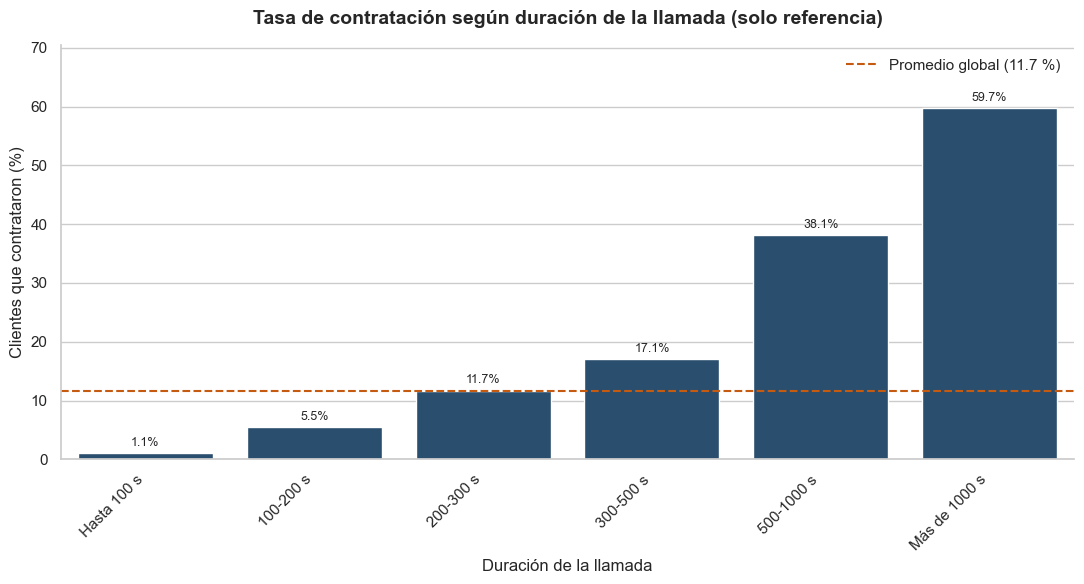

In [62]:
bins_duracion = [0, 100, 200, 300, 500, 1000, 5000]
etiquetas_duracion = ["Hasta 100 s", "100-200 s", "200-300 s", "300-500 s", "500-1000 s", "Más de 1000 s"]
df["rango_duracion"] = pd.cut(df["duration"], bins=bins_duracion, labels=etiquetas_duracion)

tabla_duracion = tasa_por_categoria(df, "rango_duracion", orden=etiquetas_duracion)
display(tabla_duracion)
grafico_tasa(tabla_duracion, "Tasa de contratación según duración de la llamada (solo referencia)",
             "Duración de la llamada")

## 9. Conclusión precisa del análisis bivariado

### Hallazgos principales (ordenados por fuerza de asociación)

1. **El historial de campaña anterior es el factor más fuerte** (V de Cramér = 0,31). Clientes que dijeron "sí" antes contratan al **64,7 %**, frente al 9,2 % de los que no tienen historial. Es la señal más útil para priorizar llamadas.

2. **El mes del último contacto es el segundo factor más fuerte** (V = 0,26). Marzo, septiembre, octubre y diciembre tienen tasas de 44 % a 52 %, mientras que mayo tiene 6,7 %. La efectividad depende del momento, no solo del volumen de llamadas.

3. **El canal de contacto, el préstamo de vivienda y la ocupación tienen fuerza moderada** (V entre 0,14 y 0,15). Tener hipoteca reduce la tasa de 16,7 % a 7,7 %. Los estudiantes (28,7 %) y jubilados (22,8 %) contratan mucho más que trabajadores manuales (7,3 %).

4. **Estado civil, educación y préstamo personal tienen fuerza débil** (V ≈ 0,07). Son significativos, pero aportan poca información por sí solos.

5. **El crédito en mora tiene fuerza prácticamente nula** (V = 0,02), aunque es estadísticamente significativo.

### Patrones que las tablas simples no muestran

- **La edad tiene forma de U.** Los menores de 25 (24 %) y los mayores de 65 (42,6 %) contratan mucho más que el grupo de 36 a 55 años (9,4 %). Por eso la comparación de medianas no detectó diferencia.
- **El saldo sube de forma constante con la tasa.** Del primer al cuarto cuartil, la tasa pasa de 7,2 % a 16,2 %.
- **Más contactos en la campaña reducen la tasa.** De 14,6 % con un solo contacto a 3,9 % con más de 10. Insistir demasiado no compensa.
- **El efecto de la hipoteca es consistente.** Reduce la tasa en los tres niveles conocidos del resultado anterior (de 70,1 % a 52,9 % con éxito previo, de 23,1 % a 8,3 % con fracaso). No es un artefacto de otra variable.
- **La ocupación y la educación interactúan.** Un jubilado con estudios superiores (27,6 %) se parece más a un estudiante (26,5 %-29,7 %) que a otro jubilado con secundaria (21,0 %).

### Limitaciones que deben tenerse en cuenta

- **`duration` no puede usarse para predecir.** Es la variable con mayor diferencia entre grupos (llamadas de más de 1.000 s tienen 59,7 % de contratación), pero solo se conoce después de la llamada. Usarla inflaría los resultados del modelo sin utilidad práctica.
- **Las correlaciones entre variables numéricas son débiles.** La mayoría están cerca de cero. La excepción es `pdays` con `previous` (0,99), que son redundantes.
- **Algunos grupos son pequeños.** Los mayores de 65 (751 clientes), los contactos previos de más de 10 (294) y el crédito en mora (815) tienen tasas que pueden variar mucho.
- **La categoría `unknown` distorsiona algunas lecturas.** Afecta a `poutcome` (82 % de los datos) y a `contact` (29 %). Sus tasas no deben interpretarse como grupos reales.
- **Los datos son de un solo banco, de 2008 a 2010.** Los patrones pueden no aplicarse a otros mercados ni a la actualidad.

### Conclusión

La contratación del depósito se explica mejor por **el historial del cliente con el banco y el momento de la campaña** que por sus datos demográficos. Las variables que más distinguen a los clientes son el resultado de la campaña anterior, el mes del contacto, la situación de deuda (hipoteca y préstamo personal) y la ocupación. La edad no tiene una relación lineal con la contratación, pero los extremos de edad sí contratan mucho más. Los clientes con más saldo contratan más, y las campañas con muchas llamadas a un mismo cliente pierden efectividad.

Para el modelo, las variables prioritarias son `poutcome`, `month`, `housing`, `job`, `contact`, `balance` y la edad en rangos. `duration` debe excluirse de la predicción y `pdays` y `previous` deben tratarse como una sola señal.